Sprint 09

Comparación de escenarios e importancia de variables para predecir el FCL preliminar.

Se evalúan empresas no financieras con corrección de persistencia y boosting de pérdida absoluta.

In [1]:
import json
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'reports/sprint_09/experimento_final').is_dir())
RAMA = 'sprint-09-variantes-importancia'

def git(*args):
    r = subprocess.run(['git', '-C', str(ROOT), *args], capture_output=True, text=True)
    return r.stdout.strip() if r.returncode == 0 else 'no disponible'

estado = git('status', '--porcelain').splitlines()
display(pd.DataFrame({'Elemento': [
    'Rama activa', 'Commit local', 'Commit remoto registrado', 'Commits sobre main',
    'Archivos modificados sin commit', 'Archivos nuevos sin commit'], 'Valor': [
    git('branch', '--show-current'), git('rev-parse', '--short', 'HEAD'),
    git('rev-parse', '--short', f'origin/{RAMA}'), git('rev-list', '--count', 'main..HEAD'),
    sum(not l.startswith('??') for l in estado), sum(l.startswith('??') for l in estado)]}))

,Elemento,Valor
0,Rama activa,sprint-09-variantes-importancia
1,Commit local,9e1fee3
2,Commit remoto registrado,9e1fee3
3,Commits sobre main,4
4,Archivos modificados sin commit,1
5,Archivos nuevos sin commit,14


Rama: sprint-09-variantes-importancia. Esta entrega permanece local, sin commit.

Objetivo: FCO(t+1) + CAPEX reportado(t+1), con CAPEX no positivo. No equivale a FCFF validado.

In [2]:
FINAL = ROOT / 'reports/sprint_09/experimento_final'
ALINEACION = ROOT / 'reports/sprint_09/alineacion_investigacion'
IMPORTANCIA = FINAL / 'importancia_procedimiento_final'
pred = pd.read_csv(FINAL / 'predicciones.csv', dtype={'RPJ': 'string'})
resumen = pd.read_csv(FINAL / 'resumen_procedimientos.csv')
comparaciones = pd.read_csv(FINAL / 'resumen_comparaciones.csv')
anuales = pd.read_csv(FINAL / 'metricas_por_anio.csv')
pd.options.display.float_format = '{:,.2f}'.format
MONEDAS = {'D lares': 'Dólares', 'Soles': 'Soles'}
TINTA, AZUL, NARANJA, AQUA, GRIS = '#52514e', '#2a78d6', '#eb6834', '#1baf7a', '#a3a29c'
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'axes.edgecolor': GRIS, 'axes.labelcolor': TINTA,
                     'xtick.color': TINTA, 'ytick.color': TINTA, 'text.color': TINTA})

def tabla_moneda(t):
    return t.assign(moneda=t.moneda.replace(MONEDAS)).rename(columns={'moneda': 'Moneda'})

muestra = pred[pred.procedimiento.eq('persistencia')]
display(tabla_moneda(muestra.groupby('moneda', as_index=False).agg(
    Observaciones=('id_fila', 'size'), Empresas=('RPJ', 'nunique'),
    Primer_año=('anio_objetivo', 'min'), Último_año=('anio_objetivo', 'max'))))

,Moneda,Observaciones,Empresas,Primer_año,Último_año
0,Dólares,119,30,2017,2021
1,Soles,547,128,2017,2021


Se excluyen bancos, seguros, financieras y AFP. Soles y dólares se evalúan por separado.

Validación temporal anidada en 2017–2021. Criterio: RMSE al menos 1 % menor, mejora en 4 de 5 años y MAE no mayor. Resultados exploratorios; no se usa 2022–2025.

In [3]:
busquedas = pd.read_csv(FINAL / 'busquedas_internas.csv')
for col in busquedas.columns:
    if col.startswith('rmse_') and col[5:].isdigit():
        assert (busquedas.loc[busquedas[col].notna(), 'anio_externo'] > int(col[5:])).all()
assert pred.anio_objetivo.between(2017, 2021).all()
assert comparaciones.groupby('moneda').size().eq(156).all()
print('Selección interna anterior a cada año externo; 156 comparaciones por moneda.')

Selección interna anterior a cada año externo; 156 comparaciones por moneda.


E0–E3 usan las mismas filas y el mismo protocolo; cambia el conjunto de atributos.

In [4]:
import sys
sys.path.insert(0, str(ROOT))
import src.variantes_importancia as vi
B, V = vi.bloques(), vi.variantes()
escenarios = pd.DataFrame({
    'Escenario': ['E0', 'E1', 'E2', 'E3'],
    'Información': ['Financiera', 'Financiera + macroeconómica',
                    'Financiera + macroeconómica + bursátil', 'Financiera + bursátil'],
    'Atributos': [len(V[e]) for e in ['E0', 'E1', 'E2', 'E3']]})
display(escenarios)
display(pd.DataFrame({'Bloque': ['Macroeconómico', 'Bursátil'],
                      'Atributos': [', '.join(B['macroeconomico']), ', '.join(B['bursatil'])]}))
display(pd.DataFrame({
    'Formulación': ['Directa', 'Corrección de persistencia', 'Relativa al activo'],
    'Objetivo de entrenamiento': ['FCL(t+1)', 'FCL(t+1) − FCL(t)', 'FCL(t+1) / Activo(t)'],
    'Uso en este notebook': ['Comparación', 'Procedimiento principal; si falta FCL(t) se usa la media de entrenamiento',
                             'Diagnóstico secundario; unidades activo-flujo no acreditadas']}))

,Escenario,Información,Atributos
0,E0,Financiera,19
1,E1,Financiera + macroeconómica,23
2,E2,Financiera + macroeconómica + bursátil,26
3,E3,Financiera + bursátil,22


,Bloque,Atributos
0,Macroeconómico,"inflacion_lima_dic_dic_pct, tipo_cambio_promed..."
1,Bursátil,"rentabilidad_indice_anual_pct, volatilidad_dia..."


,Formulación,Objetivo de entrenamiento,Uso en este notebook
0,Directa,FCL(t+1),Comparación
1,Corrección de persistencia,FCL(t+1) − FCL(t),Procedimiento principal; si falta FCL(t) se us...
2,Relativa al activo,FCL(t+1) / Activo(t),Diagnóstico secundario; unidades activo-flujo ...


Los errores se evalúan en moneda reportada. Se destaca la corrección de persistencia con boosting absoluto.

Comparación de escenarios

E0–E3 frente a persistencia y media histórica.

In [5]:
PROC = {f'persistencia|boosting_abs:{e}': e for e in ['E0', 'E1', 'E2', 'E3']}
REF = {'persistencia': 'Persistencia simple', 'media_historica': 'Media histórica'}
t = resumen[resumen.procedimiento.isin({**PROC, **REF})].copy()
t['Escenario'] = t.procedimiento.map({**PROC, **REF})
t['orden'] = t.procedimiento.map({p: i for i, p in enumerate([*PROC, *REF])})
tabla_escenarios = tabla_moneda(t.sort_values(['moneda', 'orden']))[
    ['Moneda', 'Escenario', 'anios', 'n', 'RMSE_anual_medio', 'MAE_anual_medio']].rename(columns={
    'anios': 'Años', 'n': 'Filas', 'RMSE_anual_medio': 'RMSE anual medio', 'MAE_anual_medio': 'MAE anual medio'})
display(tabla_escenarios.reset_index(drop=True))

,Moneda,Escenario,Años,Filas,RMSE anual medio,MAE anual medio
0,Dólares,E0,5,119,"191,344.22","87,996.00"
1,Dólares,E1,5,119,"188,714.03","85,587.75"
2,Dólares,E2,5,119,"189,669.39","86,386.07"
3,Dólares,E3,5,119,"190,037.75","87,490.47"
4,Dólares,Persistencia simple,5,119,"192,066.28","89,316.41"
5,Dólares,Media histórica,5,119,"288,695.50","151,261.37"
6,Soles,E0,5,547,"235,340.18","75,841.40"
7,Soles,E1,5,547,"233,620.76","75,331.16"
8,Soles,E2,5,547,"234,267.05","75,829.12"
9,Soles,E3,5,547,"234,934.11","75,741.17"


E1 presenta el menor error entre los cuatro escenarios destacados, en ambas monedas.

In [6]:
COLUMNAS = {'delta_RMSE_anual_medio_pct': 'Cambio RMSE (%)', 'delta_MAE_anual_medio_pct': 'Cambio MAE (%)',
            'anios_mejora_RMSE': 'Años con mejora', 'peor_anio_delta_RMSE_pct': 'Peor año (%)',
            'cumple_regla': 'Cumple criterio'}
PARES = [('E1', 'E0', 'Macroeconómico'), ('E3', 'E0', 'Bursátil sobre financiero'),
         ('E2', 'E1', 'Bursátil sobre financiero + macro'), ('E2', 'E0', 'Conjunto')]

def contrastes(pares):
    filas = []
    for cand, comp, aporte in pares:
        f = comparaciones[comparaciones.candidato.eq(cand) & comparaciones.comparador.eq(comp)].assign(Aporte=aporte)
        assert len(f) == 2, (cand, comp)
        filas.append(f)
    return tabla_moneda(pd.concat(filas).sort_values('moneda', kind='stable'))

pares_escenarios = contrastes([(f'persistencia|boosting_abs:{a}', f'persistencia|boosting_abs:{b}', n) for a, b, n in PARES])
display(pares_escenarios[['Moneda', 'Aporte', *COLUMNAS]].rename(columns=COLUMNAS).reset_index(drop=True))

,Moneda,Aporte,Cambio RMSE (%),Cambio MAE (%),Años con mejora,Peor año (%),Cumple criterio
0,Dólares,Macroeconómico,-1.37,-2.74,4,0.85,True
1,Dólares,Bursátil sobre financiero,-0.68,-0.57,3,1.45,False
2,Dólares,Bursátil sobre financiero + macro,0.51,0.93,2,6.14,False
3,Dólares,Conjunto,-0.88,-1.83,2,1.25,False
4,Soles,Macroeconómico,-0.73,-0.67,4,1.16,False
5,Soles,Bursátil sobre financiero,-0.17,-0.13,4,2.57,False
6,Soles,Bursátil sobre financiero + macro,0.28,0.66,1,1.53,False
7,Soles,Conjunto,-0.46,-0.02,3,2.22,False


Solo el aporte macroeconómico en dólares cumple el criterio. En soles reduce el RMSE 0,73 %. Añadir bursátiles no cumple.

In [7]:
frente_ref = contrastes([(p, r, f'{e} frente a {REF[r].lower()}') for p, e in PROC.items() for r in REF])
display(frente_ref[['Moneda', 'Aporte', *COLUMNAS]].rename(columns={**COLUMNAS, 'Aporte': 'Contraste'}).reset_index(drop=True))

,Moneda,Contraste,Cambio RMSE (%),Cambio MAE (%),Años con mejora,Peor año (%),Cumple criterio
0,Dólares,E0 frente a persistencia simple,-0.38,-1.48,3,1.99,False
1,Dólares,E0 frente a media histórica,-33.72,-41.83,4,35.56,True
2,Dólares,E1 frente a persistencia simple,-1.75,-4.17,5,-0.15,True
3,Dólares,E1 frente a media histórica,-34.63,-43.42,4,36.71,True
4,Dólares,E2 frente a persistencia simple,-1.25,-3.28,3,0.82,False
5,Dólares,E2 frente a media histórica,-34.30,-42.89,4,36.62,True
6,Dólares,E3 frente a persistencia simple,-1.06,-2.04,4,0.44,True
7,Dólares,E3 frente a media histórica,-34.17,-42.16,4,37.53,True
8,Soles,E0 frente a persistencia simple,-0.33,-2.61,4,10.41,False
9,Soles,E0 frente a media histórica,-20.36,-30.16,4,30.96,True


Todos superan a la media histórica. Frente a persistencia cumplen E1 en ambas monedas y E3 en dólares.

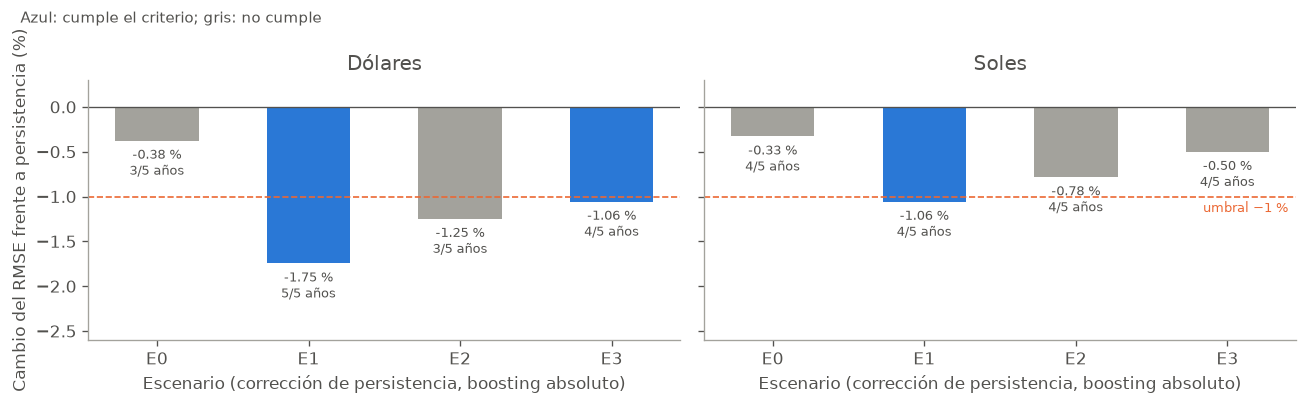

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (moneda, etiqueta) in zip(axs, MONEDAS.items()):
    f = frente_ref[frente_ref.Moneda.eq(etiqueta) & frente_ref.comparador.eq('persistencia')]
    esc = f.candidato.map(PROC)
    colores = [AZUL if c else GRIS for c in f.cumple_regla]
    ax.bar(esc, f.delta_RMSE_anual_medio_pct, color=colores, width=0.55)
    ax.axhline(0, color=TINTA, lw=0.8)
    ax.axhline(-1, color=NARANJA, lw=1, ls='--')
    for x, (v, a) in enumerate(zip(f.delta_RMSE_anual_medio_pct, f.anios_mejora_RMSE)):
        ax.annotate(f'{v:.2f} %\n{a}/5 años', (x, v), xytext=(0, -4), textcoords='offset points',
                    ha='center', va='top', fontsize=8)
    ax.set(title=etiqueta, xlabel='Escenario (corrección de persistencia, boosting absoluto)', ylim=(-2.6, 0.3))
axs[0].set_ylabel('Cambio del RMSE frente a persistencia (%)')
axs[1].text(3.4, -1.05, 'umbral −1 %', color=NARANJA, fontsize=8, ha='right', va='top')
fig.suptitle('Azul: cumple el criterio; gris: no cumple', x=0.02, ha='left', fontsize=9)
fig.tight_layout()
plt.show()

Se compara la corrección de persistencia con la predicción directa, manteniendo modelo y escenario.

In [9]:
formulacion = contrastes([(f'persistencia|boosting_abs:{e}', f'directa|boosting_abs:{e}', e) for e in PROC.values()])
display(formulacion[['Moneda', 'Aporte', *COLUMNAS]].rename(columns={**COLUMNAS, 'Aporte': 'Escenario'}).reset_index(drop=True))

,Moneda,Escenario,Cambio RMSE (%),Cambio MAE (%),Años con mejora,Peor año (%),Cumple criterio
0,Dólares,E0,-15.69,-16.05,4,119.99,True
1,Dólares,E1,-16.82,-19.44,4,114.14,True
2,Dólares,E2,-15.99,-18.04,4,127.40,True
3,Dólares,E3,-15.84,-16.08,4,116.24,True
4,Soles,E0,-7.30,-3.71,4,48.68,True
5,Soles,E1,-8.62,-5.56,4,44.77,True
6,Soles,E2,-7.51,-3.81,4,49.39,True
7,Soles,E3,-8.72,-5.25,4,43.14,True


Cambiar la formulación reduce el RMSE entre 15,7 % y 16,8 % en dólares y entre 7,3 % y 8,7 % en soles. El aporte externo es menor.

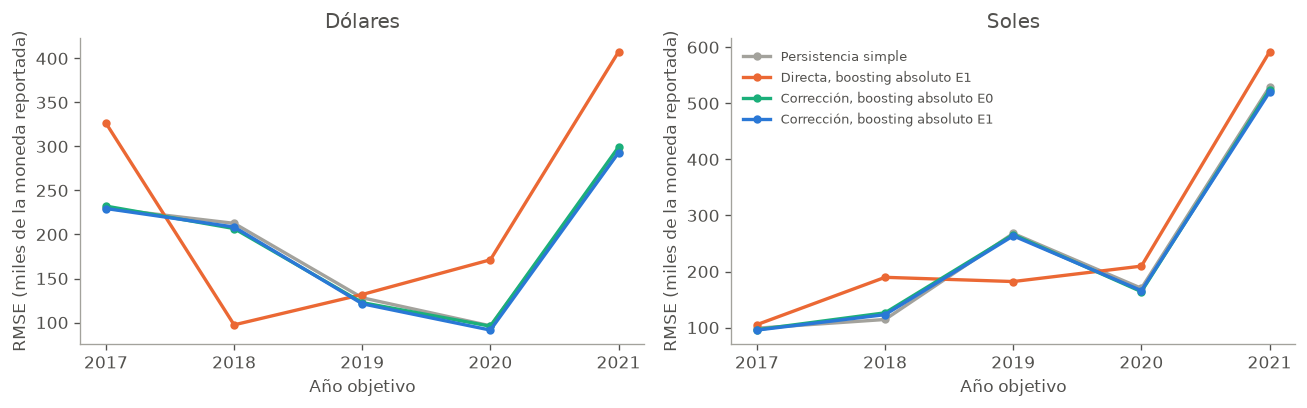

In [10]:
NOMBRES = {'persistencia': 'Persistencia simple', 'directa|boosting_abs:E1': 'Directa, boosting absoluto E1',
           'persistencia|boosting_abs:E0': 'Corrección, boosting absoluto E0',
           'persistencia|boosting_abs:E1': 'Corrección, boosting absoluto E1'}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (moneda, etiqueta) in zip(axs, MONEDAS.items()):
    for (proc, nombre), color in zip(NOMBRES.items(), [GRIS, NARANJA, AQUA, AZUL]):
        g = anuales[anuales.moneda.eq(moneda) & anuales.procedimiento.eq(proc)].sort_values('anio_externo')
        ax.plot(g.anio_externo, g.RMSE / 1e3, marker='o', ms=4, lw=2, color=color, label=nombre)
    ax.set(title=etiqueta, xlabel='Año objetivo', ylabel='RMSE (miles de la moneda reportada)')
    ax.set_xticks(range(2017, 2022))
axs[1].legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

La formulación relativa es solo diagnóstica: la compatibilidad de escala entre activo y flujo no está acreditada.

In [11]:
diag = resumen[resumen.procedimiento.str.endswith(':E1') & ~resumen.procedimiento.str.startswith('referencia')].copy()
diag[['Formulación', 'Modelo']] = diag.procedimiento.str.extract(r'^(\w+)\|(\w+):')
diag = diag.pivot_table(index=['Modelo', 'Formulación'], columns='moneda', values='RMSE_anual_medio')
display(diag.rename(columns=MONEDAS).reindex(['directa', 'persistencia', 'relativa'], level=1)
        .style.format('{:,.0f}').set_caption('RMSE anual medio en E1 por formulación y modelo'))

Los ratios extremos elevan el error relativo en soles. Esta formulación no sustenta la conclusión.

Importancia de variables

Antecedente: retirada de atributos en E2T con predicción directa; no corresponde al procedimiento final.

In [12]:
importancia_previa = pd.read_csv(ALINEACION / 'importancia_individual.csv')
bloques_previos = pd.read_csv(ALINEACION / 'importancia_bloques.csv')
top_previo = (importancia_previa[importancia_previa.modelo.eq('boosting')]
              .sort_values(['moneda', 'delta_RMSE_pct_medio'], ascending=[True, False])
              .groupby('moneda', sort=False).head(5))
display(tabla_moneda(top_previo)[['Moneda', 'retirado', 'delta_RMSE_pct_medio', 'anios_aporta']].rename(columns={
    'retirado': 'Atributo retirado', 'delta_RMSE_pct_medio': 'Aumento medio RMSE (%)', 'anios_aporta': 'Años con aporte'})
    .reset_index(drop=True))
display(tabla_moneda(bloques_previos[bloques_previos.modelo.eq('boosting')])[
    ['Moneda', 'retirado', 'delta_RMSE_pct_medio', 'anios_aporta']].rename(columns={
    'retirado': 'Bloque retirado', 'delta_RMSE_pct_medio': 'Aumento medio RMSE (%)', 'anios_aporta': 'Años con aporte'})
    .reset_index(drop=True))

,Moneda,Atributo retirado,Aumento medio RMSE (%),Años con aporte
0,Dólares,fco_activo,1.46,2
1,Dólares,crecimiento_TotalIngreso,1.24,4
2,Dólares,FCO_std3_previa,1.19,3
3,Dólares,FCL_preliminar_lag1,0.65,3
4,Dólares,volatilidad_diaria_anualizada_pct,0.16,2
5,Soles,FCO_std3_previa,7.26,3
6,Soles,log_activo_total,4.79,3
7,Soles,crecimiento_ActivoTotal,2.84,4
8,Soles,FCO_lag1,2.58,4
9,Soles,fco_ingresos,1.60,4


,Moneda,Bloque retirado,Aumento medio RMSE (%),Años con aporte
0,Dólares,bursatil,-0.24,2
1,Dólares,financiero,20.14,4
2,Dólares,macroeconomico,-0.78,3
3,Dólares,tamano,-1.28,2
4,Soles,bursatil,-0.02,2
5,Soles,financiero,18.39,4
6,Soles,macroeconomico,-0.26,2
7,Soles,tamano,4.79,3


Importancia final: se retiran atributos y bloques de E1 y se reajusta con hiperparámetros congelados. Se conserva FCL(t) como base; no se selecciona otro modelo.

In [13]:
imp_anual = pd.read_csv(IMPORTANCIA / 'importancia_por_anio.csv')
imp = pd.read_csv(IMPORTANCIA / 'importancia_resumen.csv')
verif = json.loads((IMPORTANCIA / 'verificacion.json').read_text(encoding='utf-8'))
met_final = anuales[anuales.procedimiento.eq('persistencia|boosting_abs:E1')].set_index(['moneda', 'anio_externo']).sort_index()
completo = imp_anual.drop_duplicates(['moneda', 'anio_externo']).set_index(['moneda', 'anio_externo']).sort_index()
np.testing.assert_allclose(completo[['RMSE_completo', 'MAE_completo']].to_numpy(), met_final[['RMSE', 'MAE']].to_numpy(), rtol=1e-9)
assert imp_anual.groupby(['moneda', 'retirado']).anio_externo.nunique().eq(5).all()
assert imp_anual.groupby(['moneda', 'anio_externo']).size().eq(25).all()
display(pd.DataFrame({
    'Comprobación': ['Filas externas por moneda', 'Diferencia relativa máxima con las predicciones auditadas',
                     'Años por atributo y moneda', 'Retiros por moneda y año (23 atributos y 2 bloques)'],
    'Resultado': [str({MONEDAS[k]: v for k, v in verif['filas_por_moneda'].items()}),
                  f"{verif['max_diferencia_relativa_prediccion_completa']:.1e}", 5, 25]}))

,Comprobación,Resultado
0,Filas externas por moneda,"{'Dólares': 119, 'Soles': 547}"
1,Diferencia relativa máxima con las prediccione...,4.5e-15
2,Años por atributo y moneda,5
3,Retiros por moneda y año (23 atributos y 2 blo...,25


El modelo completo reproduce E1. Un delta positivo indica que retirar el atributo aumenta el error.

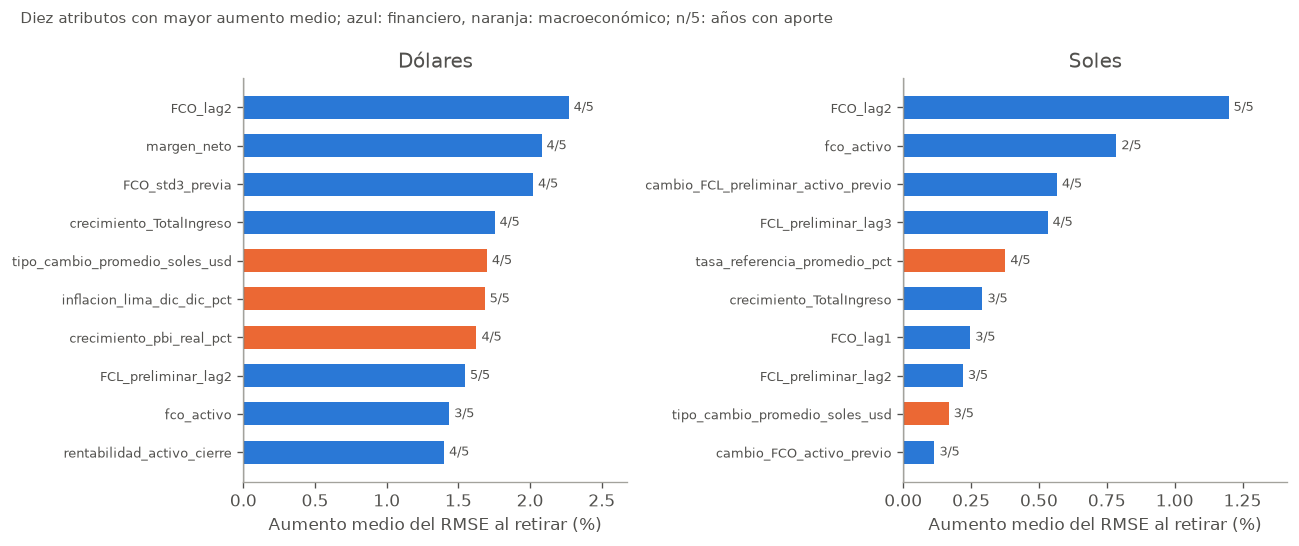

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (moneda, etiqueta) in zip(axs, MONEDAS.items()):
    g = (imp[imp.moneda.eq(moneda) & imp.tipo.eq('individual')]
         .sort_values('delta_RMSE_pct_medio', ascending=False).head(10).iloc[::-1])
    macro = g.retirado.isin(B['macroeconomico'])
    ax.barh(g.retirado, g.delta_RMSE_pct_medio, color=np.where(macro, NARANJA, AZUL), height=0.6)
    ax.axvline(0, color=TINTA, lw=0.8)
    for y, (v, a) in enumerate(zip(g.delta_RMSE_pct_medio, g.anios_aporta)):
        ax.annotate(f'{a}/5', (max(v, 0), y), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8)
    ax.set(title=etiqueta, xlabel='Aumento medio del RMSE al retirar (%)')
    ax.tick_params(axis='y', labelsize=8)
    ax.set_xlim(right=g.delta_RMSE_pct_medio.max() * 1.18)
fig.suptitle('Diez atributos con mayor aumento medio; azul: financiero, naranja: macroeconómico; n/5: años con aporte',
             x=0.02, ha='left', fontsize=9)
fig.tight_layout()
plt.show()

In [15]:
COL_IMP = {'retirado': 'Bloque retirado', 'delta_RMSE_pct_medio': 'Aumento medio RMSE (%)',
           'delta_RMSE_pct_min': 'Mínimo anual (%)', 'delta_RMSE_pct_max': 'Máximo anual (%)',
           'delta_MAE_pct_medio': 'Aumento medio MAE (%)', 'anios_aporta': 'Años con aporte', 'aporte_estable': 'Aporte estable'}
display(tabla_moneda(imp[imp.tipo.eq('bloque')])[['Moneda', *COL_IMP]].rename(columns=COL_IMP).reset_index(drop=True))
anual_bloques = imp_anual[imp_anual.tipo.eq('bloque')].pivot_table(index=['moneda', 'retirado'], columns='anio_externo', values='delta_RMSE_pct')
display(anual_bloques.rename(index=MONEDAS).style.format('{:+.2f}').set_caption('Aumento del RMSE al retirar cada bloque, por año (%)'))
estables = imp[imp.tipo.eq('individual') & imp.aporte_estable].groupby('moneda').size().reindex(list(MONEDAS), fill_value=0)
print('Atributos individuales con aporte estable (4 de 5 años y al menos 1 %):', {MONEDAS[k]: int(v) for k, v in estables.items()}, 'de 23')

,Moneda,Bloque retirado,Aumento medio RMSE (%),Mínimo anual (%),Máximo anual (%),Aumento medio MAE (%),Años con aporte,Aporte estable
0,Dólares,financiero,1.99,-0.59,5.23,5.45,3,False
1,Dólares,macroeconomico,1.68,0.22,4.83,2.72,5,True
2,Soles,financiero,0.49,-7.01,3.55,3.20,4,False
3,Soles,macroeconomico,0.06,-1.09,2.09,-0.04,2,False


Atributos individuales con aporte estable (4 de 5 años y al menos 1 %): {'Dólares': 14, 'Soles': 1} de 23


Retirar macroeconomía aumenta el RMSE en dólares 1,68 % promedio, en los cinco años. En soles no hay aporte estable. El ranking es condicional al modelo y no implica causalidad.

Matriz de consistencia

Propuesta del componente predictivo; no sustituye las hipótesis originales de valoración DCF.

| Problema | Objetivo | Hipótesis | Variables independientes y dependiente | Indicadores |
|---|---|---|---|---|
| General: ¿la información financiera, macroeconómica y bursátil del año t permite predecir el FCL preliminar del año siguiente con menos error que las referencias simples, en empresas no financieras? | Evaluar con validación temporal anidada, por moneda, si algún procedimiento supera a persistencia y a la media histórica | HG: al menos un procedimiento reduce el RMSE anual medio en 1 % o más frente a ambas referencias, en 4 de 5 años, sin aumentar el MAE | Independientes: atributos financieros, macroeconómicos y bursátiles del año t. Dependiente: FCL preliminar(t+1). Factores: formulación, modelo y escenario | RMSE y MAE anuales medios; cambio porcentual frente a referencias; años con mejora |
| Específico macroeconómico: ¿la información macroeconómica mejora la predicción frente a solo información financiera? | Comparar E1 con E0 con el mismo procedimiento | H1p: E1 cumple el criterio frente a E0 | Independientes: 19 atributos financieros y 4 macroeconómicos del año t. Dependiente: FCL preliminar(t+1). Factor: escenario | Cambio del RMSE y del MAE de E1 frente a E0; años con mejora |
| Específico bursátil: ¿la información bursátil mejora la predicción sobre la financiera y sobre la financiera con macroeconomía? | Comparar E3 con E0 y E2 con E1 | H2p: E3 cumple frente a E0, o E2 cumple frente a E1 | Independientes: atributos financieros, 3 bursátiles y, en E2, macroeconómicos del año t. Dependiente: FCL preliminar(t+1). Factor: escenario | Cambio del RMSE y del MAE de E3 frente a E0 y de E2 frente a E1; años con mejora |
| Específico importancia: ¿qué atributos y bloques sostienen el desempeño del procedimiento final? | Medir la retirada con reajuste en la corrección de persistencia con boosting absoluto E1 | H3p: algún bloque aumenta el RMSE en 4 de 5 años al retirarlo, con un aumento medio de 1 % o más | Independientes: 23 atributos de E1, individualmente y en bloques. Dependiente: FCL preliminar(t+1). Factor: atributo o bloque retirado | Aumento del RMSE al retirar; años con aporte; aumento del MAE |

HG cumple en ambas monedas con E1. H1p y H3p cumplen en dólares; H2p no cumple. Son resultados exploratorios.

[Alcance original y pendientes](../../reports/sprint_09/alineacion_investigacion/matriz_consistencia.md).

Operacionalización

| Variable | Dimensión | Medición | Unidad | Fuente |
|---|---|---|---|---|
| FCL preliminar(t+1), dependiente | Flujo futuro | FCO(t+1) + CAPEX reportado(t+1), con CAPEX no positivo | Moneda reportada, escala no acreditada | SMV |
| Atributos financieros, independientes | Rentabilidad, endeudamiento, eficiencia, crecimiento y memoria del flujo | 19 ratios, rezagos y variabilidades de FCO y FCL del año t y previos | Fracción o moneda reportada | SMV |
| Atributos macroeconómicos, independientes | Actividad, precios, política monetaria y tipo de cambio | Crecimiento porcentual anual del PBI real, inflación de Lima, tasa de referencia y tipo de cambio del año t | Porcentaje y soles por dólar | BCRP |
| Atributos bursátiles, independientes | Mercado de valores agregado | Rentabilidad del índice, volatilidad y monto negociado en renta variable del año t | Porcentaje y millones de soles | Bolsa de Valores de Lima |
| Escenario, factor experimental | Información disponible | E0, E1, E2 o E3 | Categoría | Diseño del experimento |
| RMSE y MAE, indicadores | Error de predicción | Promedio de los errores anuales 2017 a 2021 | Moneda reportada | Predicciones guardadas |

Las definiciones completas están en la [matriz de operacionalización detallada](../../reports/sprint_09/alineacion_investigacion/matriz_operacionalizacion.md) y en la [matriz del Sprint 09](../../reports/sprint_09/matriz_operacionalizacion.md).

Se verifican métricas, igualdad de muestras, cinco años por procedimiento y enlaces. No se repite el entrenamiento.

In [16]:
for fila in anuales.itertuples():
    g = pred[pred.procedimiento.eq(fila.procedimiento) & pred.moneda.eq(fila.moneda)
             & pred.anio_objetivo.eq(fila.anio_externo)]
    error = g.y_real - g.y_predicho
    np.testing.assert_allclose([fila.RMSE, fila.MAE], [np.sqrt(np.mean(error**2)), np.mean(np.abs(error))], rtol=1e-12)

filas = pred.groupby(['moneda', 'procedimiento']).id_fila.apply(lambda s: tuple(sorted(s)))
assert filas.groupby('moneda').nunique().eq(1).all()
assert anuales.groupby(['moneda', 'procedimiento']).anio_externo.nunique().eq(5).all()

esperado = resumen.set_index(['moneda', 'procedimiento'])
for r in t.itertuples():
    assert np.isclose(esperado.loc[(r.moneda, r.procedimiento), 'RMSE_anual_medio'], r.RMSE_anual_medio, rtol=0)
assert len(tabla_escenarios) == 12 and len(pares_escenarios) == 8 and len(frente_ref) == 16 and len(formulacion) == 8

nb = json.loads((ROOT / 'notebooks/sprint_09/14_presentacion_resultados.ipynb').read_text(encoding='utf-8'))
textos = [''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'markdown']
assert not any('**' in s or '__' in s for s in textos)
assert not any(l.lstrip().startswith(('- ', '* ', '+ ')) for s in textos for l in s.splitlines())
import re
enlaces = [m for s in textos for m in re.findall(r'\]\(([^)]+)\)', s)]
base = ROOT / 'notebooks/sprint_09'
assert all((base / e).resolve().is_file() for e in enlaces), enlaces
print(f'Métricas reconstruidas: {len(anuales)} filas anuales. Mismas filas por moneda: '
      f"{ {MONEDAS[k]: len(v) for k, v in filas.groupby('moneda').first().items()} }. "
      f'Cinco años por procedimiento. Enlaces verificados: {len(enlaces)}. Markdown sin negritas ni viñetas.')

Métricas reconstruidas: 380 filas anuales. Mismas filas por moneda: {'Dólares': 119, 'Soles': 547}. Cinco años por procedimiento. Enlaces verificados: 4. Markdown sin negritas ni viñetas.


La corrección de persistencia mejora la predicción. El aporte macroeconómico cumple el criterio solo en dólares; el bursátil no cumple. Faltan acreditar escala y disponibilidad temporal, y confirmar con datos no examinados.

Detalle en el [resumen técnico](../../reports/sprint_09/experimento_final/resumen_tecnico.md).